# 9 — Combined Paper Figures

Assembles main Figures 2, 3, and 4, plus supplementary figures S1–S6.

Note: `supplement_purity`, `supplement_nonresponse`, `supplement_validation`,
`supplement_correlation`, and `supplement_tumortype_forest` are produced by the assembler
scripts (`assemble_*.R`) which are called automatically by `run_figures.R`.

In [1]:
source(paste0(dirname(getwd()), "/helpers/map.r"))
source(paste0(dirname(getwd()), "/helpers/shortcuts.r"))
source(paste0(dirname(getwd()), "/helpers/config.r"))
source(paste0(dirname(getwd()), "/helpers/themes.r"))

library(patchwork)

dir.create(paste0(CIDER_PROJ_DIR, "figs/"), showWarnings = FALSE, recursive = TRUE)

fig <- function(name) readRDS(paste0(CIDER_PROJ_DIR, "figs/", name, ".rds"))

save_fig <- function(plot, fig_name, width, height) {
  saveRDS(plot, paste0(CIDER_PROJ_DIR, "figs/", fig_name, ".rds"))
  ggsave(paste0(CIDER_PROJ_DIR, "figs/", fig_name, ".png"),
         plot, width = width, height = height)
  message("Saved: ", fig_name, ".png")
}

# Figure 2 — Validation (Landscape · RNA · Purity Correction)

Saved: figure_2a.png



`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


Saved: figure_2b.png



...

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


Saved: figure_2.png



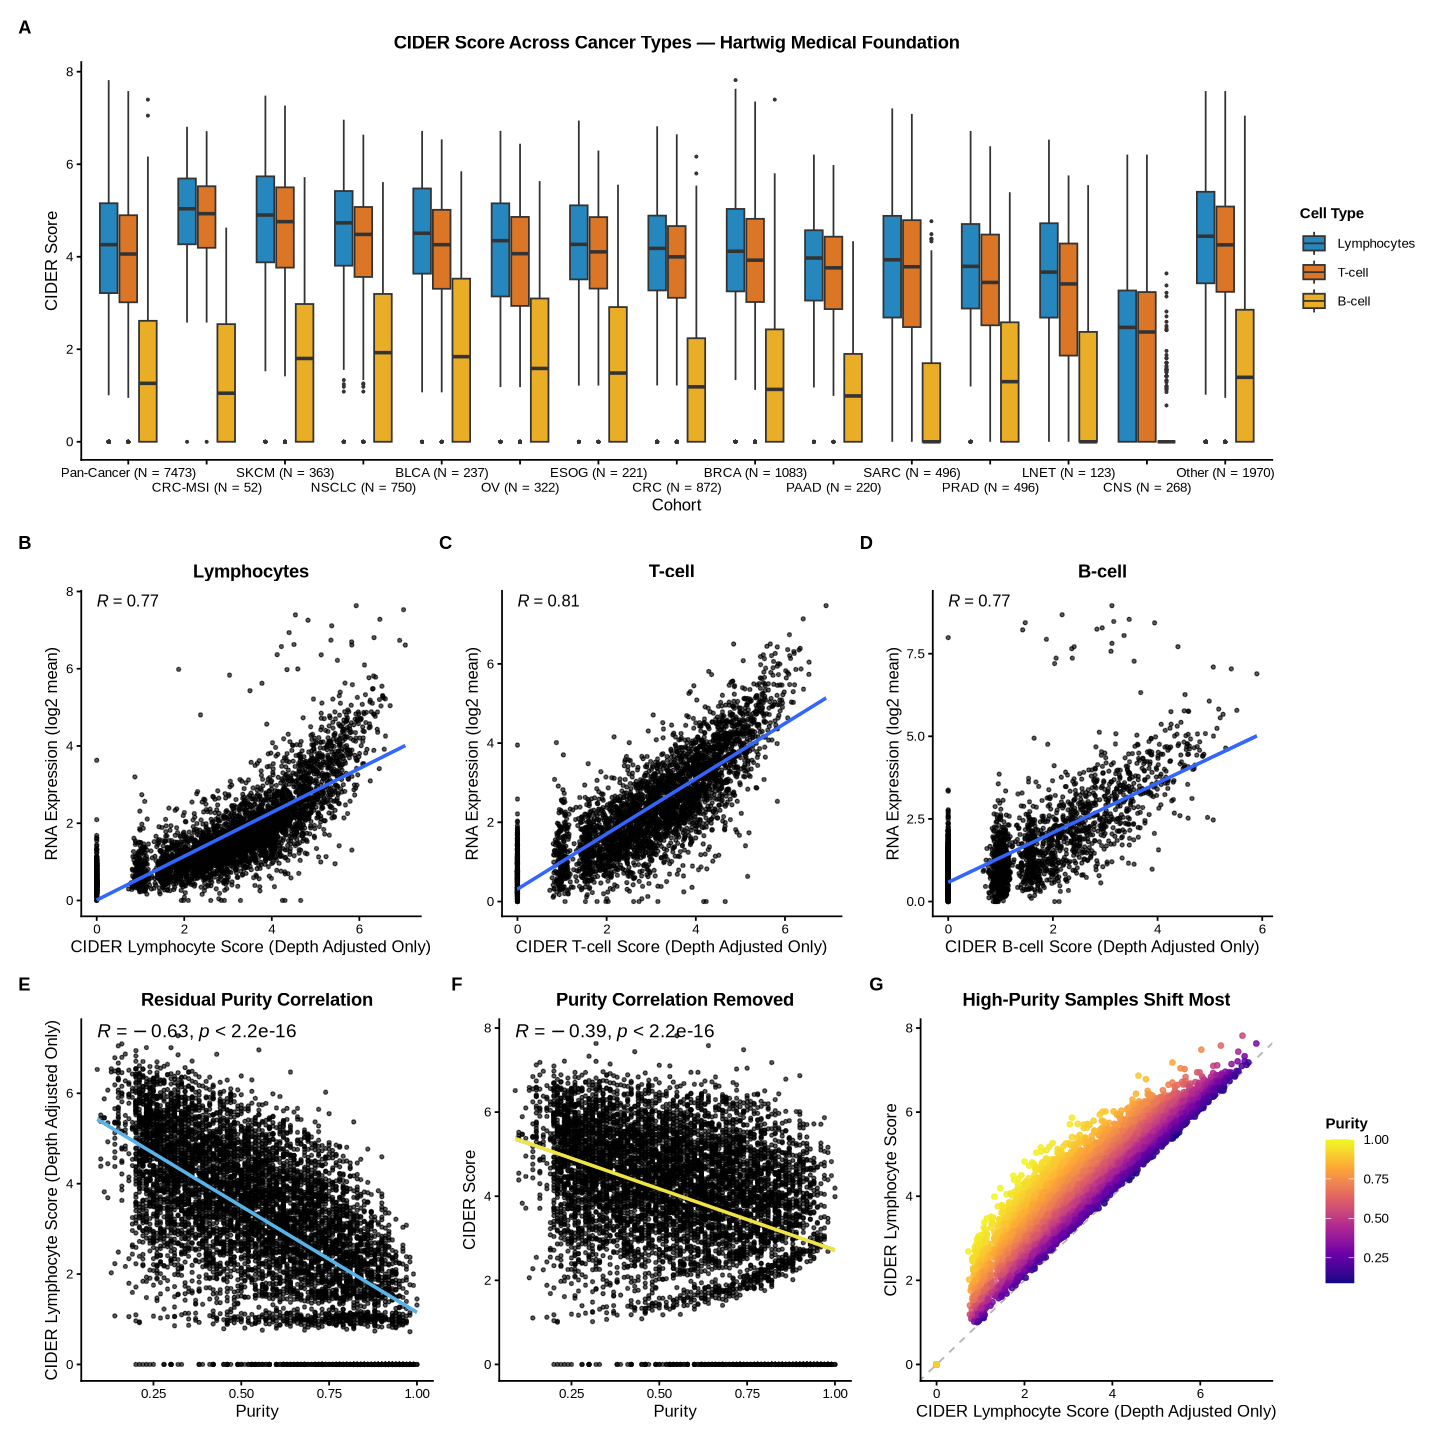

In [2]:
# ── Figure 2A: T-cell landscape ─────────────────────────────────────────────
fig2a <- fig("landscape")
save_fig(fig2a, "figure_2a", width = 12, height = 4.5)

# ── Figure 2B: RNA validation ────────────────────────────────────────────────
fig2b <- fig("tcell_validation_rna")
save_fig(fig2b, "figure_2b", width = 5, height = 4)

# ── Figure 2C: ImmuneLENS validation ────────────────────────────────────────
fig2c <- fig("tcell_validation_il")
save_fig(fig2c, "figure_2c", width = 5, height = 4)


# ── Combined Figure 2 ─────────────────────────────────────────────────────────
figure_2 <-
  fig2a /
  wrap_plots(fig2b, fig2c, nrow = 1, widths = c(0.80, 2.20)) +
  plot_layout(heights = c(1.1, 1.0)) +
  plot_annotation(
    tag_levels = "A",
    theme = go_theme + theme(
      plot.tag   = element_text(size = 14, face = "bold"),
      plot.title = element_text(hjust = 0.5, size = 14, face = "bold")
    )
  )

set_plot_dims(12, 8); figure_2
save_fig(figure_2, "figure_2", width = 12, height = 8)

# Figure 3 — CIDER Score Predicts ICI Response

In [ ]:
# ── Figure 3A: CIDER T-cell Score vs ICI Response ───────────────────────────
fig3a <- fig("main_response_figure")

# ── Figure 3B: Overall Survival by CIDER T-cell Score ───────────────────────
# Wrapped as a single patchwork unit so the outer plot_annotation assigns
# one tag (B) to the entire survival grid rather than tagging each KM panel.
fig3b <- wrap_elements(full = fig("main_survival_figure")) +
  plot_annotation(
    title = "Overall Survival vs CIDER T-cell Score",
    theme = go_theme + theme(
      plot.title = element_text(hjust = 0.5, size = 11, face = "bold")
    )
  )

# ── Combined Figure 3 ─────────────────────────────────────────────────────────
figure_3 <-
  (fig3a / fig3b) +
  plot_layout(heights = c(1, 2)) +
  plot_annotation(
    tag_levels = "A",
    theme = go_theme + theme(plot.tag = element_text(size = 14, face = "bold"))
  )

set_plot_dims(11, 12); figure_3
save_fig(figure_3, "figure_3", width = 11, height = 12)


# Figure 4 — CIDER Score Predicts Overall Survival

In [4]:
# Standalone per-cohort OS survival grid — retained for reference only.
# (merged into Figure 3 Panel B)
fig_survival_ref <- fig("main_survival_figure")
save_fig(fig_survival_ref, "figure_survival_ref", width = 11, height = 8)

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Saved: figure_4.png



# Figure 5 — Independence from and Additive Value over TMB

In [ ]:
# ── Figure 4A: CIDER Score vs TMB (orthogonality) ───────────────────────────
fig4a <- fig("tmb_vs_tcell")
save_fig(fig4a, "figure_4a", width = 4, height = 3.5)

# ── Figure 4B: CIDER × TMB — ICI-Treated single panel ───────────────────────
fig4b <- fig("pan_cancer_survival_tmb")
save_fig(fig4b, "figure_4b", width = 6, height = 6)

# ── Figure 4C: Overall pan-cancer ROC (CIDER vs TMB vs combined) ─────────────
fig4c <- fig("overall_roc")
save_fig(fig4c, "figure_4c", width = 5, height = 5)

# ── Combined Figure 4 — A: orthogonality, B: ROC, C: survival ────────────────
figure_4 <-
  (fig4a | fig4c | fig4b) +
  plot_layout(widths = c(1, 1, 1)) +
  plot_annotation(
    tag_levels = "A",
    theme = go_theme + theme(plot.tag = element_text(size = 14, face = "bold"))
  )

set_plot_dims(13, 6); figure_4
save_fig(figure_4, "figure_4", width = 13, height = 5)

# Supplementary Figures

S1–S4 below are assembled here. Additional supplementals are produced by assembler scripts:

| File | Script |
|------|--------|
| `supplement_purity.png` | `assemble_purity_figure.R` |
| `supplement_nonresponse.png` | `assemble_nonresponse_figure.R` |
| `supplement_validation.png` + `supplement_correlation.png` | `assemble_validation_figure.R` |
| `supplement_tumortype_forest.png` | `7_forest.ipynb` |

In [6]:
# ── Supplementary figures ─────────────────────────────────────────────────────
# S1 — Methodological: confounder supplement (purity + depth)
save_fig(fig("confounders_supplement"),  "figure_s1", width = 10, height = 9)
# S2 — Clinical: PFS survival
save_fig(fig("main_pfs_figure"),         "figure_s2", width = 11, height = 8)
# S3 — Clinical: T-cell and B-cell survival
save_fig(fig("supporting_survival_tcell"), "figure_s3a", width = 11, height = 8)
save_fig(fig("survival_bcell"),            "figure_s3b", width = 11, height = 8)
# S4 — Statistical: ROC curves with DeLong tests
save_fig(fig("supplement_roc"),            "figure_s4", width = 14, height = 8)

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


Saved: figure_s1.png



Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


...

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Saved: figure_s3b.png



Saved: figure_s4.png



In [ ]:
# S5 — Pan-Cancer 9-group: KM survival + response rate bar plot
figure_s5 <-
  (fig("survival_9group_pan") / fig("response_9group_pan")) +
  plot_layout(heights = c(1.5, 1)) +
  plot_annotation(
    tag_levels = "A",
    theme = go_theme + theme(plot.tag = element_text(size = 14, face = "bold"))
  )

set_plot_dims(9, 7); figure_s5
save_fig(figure_s5, "figure_s5", width = 9, height = 7)

# Figure S6 — Depth-Adjusted Score: Figure 5 Sensitivity Analysis

Reproduces Figure 5 using `cider_score_depth_adj` (depth normalised only,
no purity correction) to show sensitivity of the CIDER × TMB results to
the purity correction step.

In [ ]:
# ── Figure S6A: TMB vs CIDER Score ────────────────────
fig_s6a <- fig("tmb_vs_tcell_depth_adj")

# ── Figure S6B: CIDER (Depth Adj) × TMB — ICI-Treated KM ───────────────────
fig_s6b <- fig("pan_cancer_survival_tmb_depth_adj")

# ── Combined Figure S6 ────────────────────────────────────────────────────────
figure_s6 <-
  (fig_s6a | fig_s6b) +
  plot_layout(widths = c(1, 1.1)) +
  plot_annotation(
    title    = "Sensitivity Analysis: CIDER Score With Purity Correction",
    subtitle = "Reproduces Figure 5 using purity-corrected CIDER score",
    tag_levels = "A",
    theme = go_theme + theme(
      plot.tag      = element_text(size = 14, face = "bold"),
      plot.title    = element_text(size = 13, face = "bold"),
      plot.subtitle = element_text(size = 11)
    )
  )

set_plot_dims(11, 6); figure_s6
save_fig(figure_s6, "figure_s6", width = 11, height = 6)

# Figure 3B — Predicted ICI Response Probability Landscape